[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch07_unet.ipynb)

# 7장 영상 분할 — U-Net으로 대장 용종 분할하기 · 실습 노트북
『보고, 읽고, 설명하는 딥러닝 — Colab에서 직접 만들며 배우는 딥러닝 응용』

7.10절 실습입니다. 대장 내시경 사진에서 용종(polyp)이 있는 픽셀을 찾아내는 U-Net을 케라스로 만들고 학습합니다.
1. Kvasir-SEG 데이터 내려받기와 확인
2. U-Net 만들기
3. Dice 계수와 손실 함수
4. 학습과 학습 곡선
5. 테스트 데이터로 평가(Dice, IoU)와 예측 결과 보기
6. 실습: 지름길(skip connection)을 뺀 모델과 비교, 임계값 바꾸기

> **GPU 런타임**에서 실행하세요. 메뉴 [런타임] → [런타임 유형 변경]에서 **T4 GPU**를 고릅니다. 학습은 T4에서 약 7분, 실습 1의 두 번째 학습은 약 5분 걸립니다.

데이터: Kvasir-SEG (Simula Research Laboratory) — https://datasets.simula.no/kvasir-seg
연구·교육 목적으로만 사용할 수 있으며, 사용할 때는 다음 논문을 인용해야 합니다.
D. Jha, P. H. Smedsrud, M. A. Riegler, P. Halvorsen, T. de Lange, D. Johansen, H. D. Johansen, "Kvasir-SEG: A Segmented Polyp Dataset", *MultiMedia Modeling (MMM)*, 2020.

## 준비

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import load_img, img_to_array

tf.keras.utils.set_random_seed(42)   # 실행할 때마다 결과가 크게 달라지지 않도록
print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. 데이터 내려받기
Kvasir-SEG에는 대장 내시경 사진 1,000장과, 사진마다 용종 영역을 흰색으로 칠한 마스크(mask)가 들어 있습니다.

데이터 서버가 인증서 확인에 필요한 중간 인증서를 함께 보내지 않아서, `wget`만으로는 "인증서를 확인할 수 없다"는 오류가 납니다.
그래서 인증서 발급 기관(Sectigo)이 공개한 중간 인증서를 먼저 받아, 인증서 확인을 그대로 켠 채로 내려받습니다.
그래도 내려받기가 안 되면 브라우저로 https://datasets.simula.no/kvasir-seg 에서 `kvasir-seg.zip`을 받아 왼쪽 [파일] 창에 끌어다 놓은 뒤 `unzip` 줄부터 실행하세요.

In [ ]:
# 중간 인증서를 받아 시스템 인증서 목록에 더한다
!wget -q http://crt.sectigo.com/SectigoPublicServerAuthenticationCADVR36.crt -O sectigo.der
!openssl x509 -inform DER -in sectigo.der -out sectigo.pem
!cat /etc/ssl/certs/ca-certificates.crt sectigo.pem > ca-bundle.pem
# 데이터 내려받기(약 46MB)와 압축 풀기
!wget -q --ca-certificate=ca-bundle.pem https://datasets.simula.no/downloads/kvasir-seg.zip
!unzip -q kvasir-seg.zip
!ls Kvasir-SEG

images	kavsir_bboxes.json  masks


In [ ]:
image_paths = sorted(glob.glob('Kvasir-SEG/images/*.jpg'))
mask_paths = sorted(glob.glob('Kvasir-SEG/masks/*.jpg'))
print(len(image_paths), len(mask_paths))
print(os.path.basename(image_paths[0]), os.path.basename(mask_paths[0]))

1000 1000
cju0qkwl35piu0993l0dewei2.jpg cju0qkwl35piu0993l0dewei2.jpg


사진마다 크기가 다르므로 모두 256×256으로 맞춥니다. 사진은 0~1로, 마스크는 0(배경)과 1(용종) 두 값으로 바꿉니다.

In [ ]:
IMG_SIZE = 256

def load_pair(img_path, mask_path):
    img = img_to_array(load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))) / 255.
    mask = img_to_array(load_img(mask_path, target_size=(IMG_SIZE, IMG_SIZE),
                                 color_mode='grayscale')) / 255.
    mask = (mask > 0.5).astype('float32')     # JPEG 압축으로 생긴 중간값을 0 또는 1로
    return img, mask

pairs = [load_pair(i, m) for i, m in zip(image_paths, mask_paths)]
X = np.array([p[0] for p in pairs], dtype='float32')
Y = np.array([p[1] for p in pairs], dtype='float32')
print(X.shape, Y.shape)
print("용종 픽셀의 비율:", Y.mean())

(1000, 256, 256, 3) (1000, 256, 256, 1)
용종 픽셀의 비율: 0.1539521


1,000장을 학습 800장, 검증 100장, 테스트 100장으로 나눕니다.

In [ ]:
idx = np.random.default_rng(42).permutation(len(X))
train_idx, val_idx, test_idx = idx[:800], idx[800:900], idx[900:]
X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]
print(len(X_train), len(X_val), len(X_test))

800 100 100


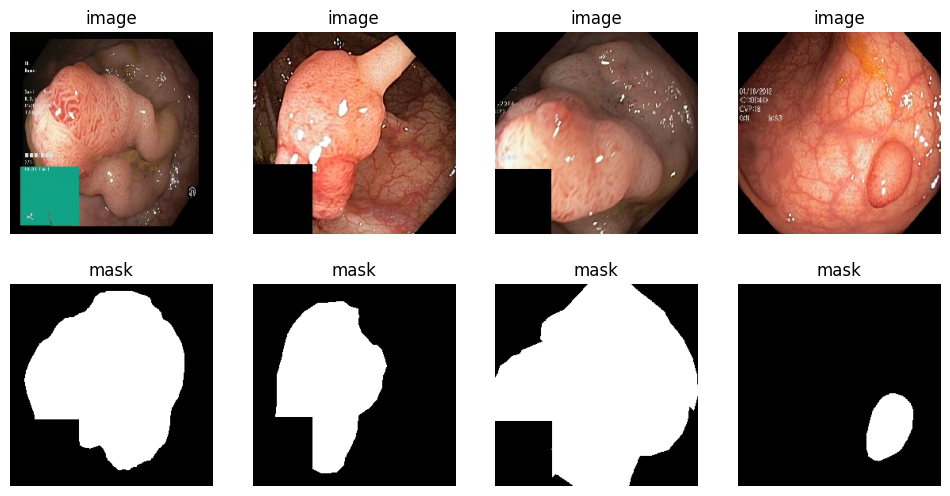

In [ ]:
plt.figure(figsize=(12, 6))
for k in range(4):
    plt.subplot(2, 4, k + 1); plt.imshow(X_train[k]); plt.axis('off'); plt.title('image')
    plt.subplot(2, 4, k + 5); plt.imshow(Y_train[k, :, :, 0], cmap='gray'); plt.axis('off'); plt.title('mask')
plt.show()

## 2. U-Net 만들기
- **수축 경로(encoder)**: 3×3 합성곱 두 번 + 2×2 최대 풀링을 반복하며 크기를 절반씩 줄이고 채널을 늘립니다.
- **확장 경로(decoder)**: 2×2 전치 합성곱(`Conv2DTranspose`)으로 크기를 두 배씩 키우고, 같은 크기의 수축 경로 특성 맵을 **이어 붙인 뒤**(`concatenate`) 3×3 합성곱 두 번을 합니다.
- **출력**: 1×1 합성곱 + 시그모이드로 픽셀마다 용종일 확률을 냅니다.

In [ ]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    return x

def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base=16, skip=True):
    inputs = layers.Input(input_shape)
    # 수축 경로: 256 → 128 → 64 → 32 → 16
    c1 = conv_block(inputs, base);       p1 = layers.MaxPooling2D(2)(c1)
    c2 = conv_block(p1, base * 2);       p2 = layers.MaxPooling2D(2)(c2)
    c3 = conv_block(p2, base * 4);       p3 = layers.MaxPooling2D(2)(c3)
    c4 = conv_block(p3, base * 8);       p4 = layers.MaxPooling2D(2)(c4)
    b = conv_block(p4, base * 16)        # 가장 아래(16×16)
    # 확장 경로: 16 → 32 → 64 → 128 → 256
    x = b
    for c, f in [(c4, base * 8), (c3, base * 4), (c2, base * 2), (c1, base)]:
        x = layers.Conv2DTranspose(f, 2, strides=2, padding='same')(x)
        if skip:
            x = layers.concatenate([x, c])   # 지름길: 수축 경로의 특성 맵을 이어 붙인다
        x = conv_block(x, f)
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(x)
    return models.Model(inputs, outputs)

model = build_unet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 1,941,105 (7.40 MB)

 Trainable params: 1,941,105 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Dice 계수와 손실 함수
Dice 계수는 예측 영역 $P$와 정답 영역 $G$가 얼마나 겹치는지를 나타냅니다. $\text{Dice} = \dfrac{2|P\cap G|}{|P| + |G|}$ (0~1, 클수록 좋음)

손실은 픽셀마다의 이진 크로스 엔트로피에 $1-\text{Dice}$를 더해 씁니다. 용종 픽셀이 전체의 일부뿐이라, 크로스 엔트로피만 쓰면 배경을 맞히는 쪽으로 치우치기 쉽기 때문입니다.

In [ ]:
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + (1. - dice_coef(y_true, y_pred))

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss=bce_dice_loss, metrics=[dice_coef])

## 4. 학습
2장에서 배운 조기 종료를 씁니다. 검증 손실이 10에포크 동안 좋아지지 않으면 멈추고, 가장 좋았던 가중치로 되돌립니다.

In [ ]:
early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                         restore_best_weights=True)
history = model.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                    epochs=60, batch_size=16, callbacks=[early], verbose=2)

Epoch 1/60
50/50 - 45s - 896ms/step - dice_coef: 0.2066 - loss: 1.2978 - val_dice_coef: 0.2751 - val_loss: 1.1569
Epoch 2/60
50/50 - 8s - 159ms/step - dice_coef: 0.2676 - loss: 1.1278 - val_dice_coef: 0.2992 - val_loss: 1.1731
Epoch 3/60
50/50 - 8s - 161ms/step - dice_coef: 0.2835 - loss: 1.1097 - val_dice_coef: 0.3015 - val_loss: 1.1443
Epoch 4/60
50/50 - 8s - 163ms/step - dice_coef: 0.2911 - loss: 1.0979 - val_dice_coef: 0.3283 - val_loss: 1.1043
Epoch 5/60
50/50 - 8s - 166ms/step - dice_coef: 0.3128 - loss: 1.0578 - val_dice_coef: 0.3416 - val_loss: 1.0498
Epoch 6/60
50/50 - 8s - 167ms/step - dice_coef: 0.3556 - loss: 1.0143 - val_dice_coef: 0.3798 - val_loss: 1.0715
Epoch 7/60
50/50 - 9s - 170ms/step - dice_coef: 0.3798 - loss: 1.0011 - val_dice_coef: 0.3611 - val_loss: 1.0185
Epoch 8/60
50/50 - 9s - 173ms/step - dice_coef: 0.3947 - loss: 0.9731 - val_dice_coef: 0.4251 - val_loss: 1.0171
Epoch 9/60
50/50 - 9s - 178ms/step - dice_coef: 0.3922 - loss: 0.9774 - val_dice_coef: 0.4196 -

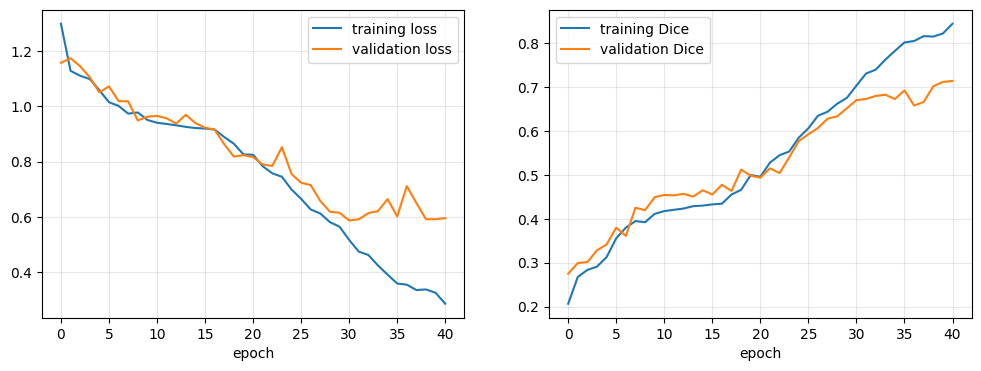

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('epoch'); plt.legend(); plt.grid(alpha=0.3)
plt.subplot(1, 2, 2)
plt.plot(history.history['dice_coef'], label='training Dice')
plt.plot(history.history['val_dice_coef'], label='validation Dice')
plt.xlabel('epoch'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. 테스트 데이터로 평가
예측 확률을 0.5 기준으로 0과 1로 바꾼 뒤, 사진마다 Dice와 IoU를 구해 평균을 냅니다. IoU는 7.2절의 상자 IoU와 같은 식을 픽셀 영역에 적용한 것입니다.

In [ ]:
def dice_iou(mask_true, mask_pred):
    inter = np.logical_and(mask_true, mask_pred).sum()
    total = mask_true.sum() + mask_pred.sum()
    union = np.logical_or(mask_true, mask_pred).sum()
    dice = 2 * inter / total if total > 0 else 1.0
    iou = inter / union if union > 0 else 1.0
    return dice, iou

prob_test = model.predict(X_test, verbose=0)
pred_test = prob_test > 0.5
scores = np.array([dice_iou(Y_test[i] > 0.5, pred_test[i]) for i in range(len(X_test))])
print(f"테스트 Dice 평균: {scores[:, 0].mean():.3f}")
print(f"테스트 IoU 평균:  {scores[:, 1].mean():.3f}")

테스트 Dice 평균: 0.662
테스트 IoU 평균:  0.563


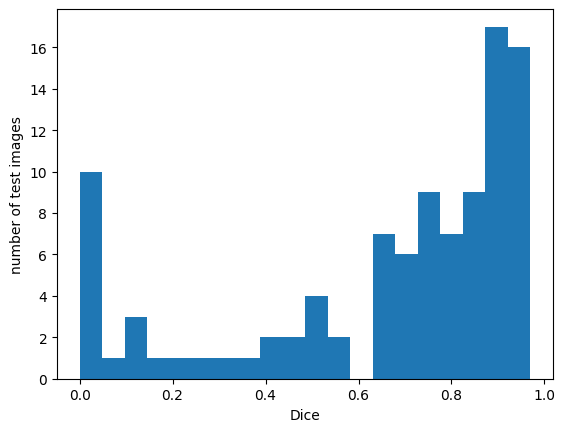

In [ ]:
plt.hist(scores[:, 0], bins=20)
plt.xlabel('Dice'); plt.ylabel('number of test images')
plt.show()

Dice가 높은 사진 3장과 낮은 사진 3장을 봅니다.

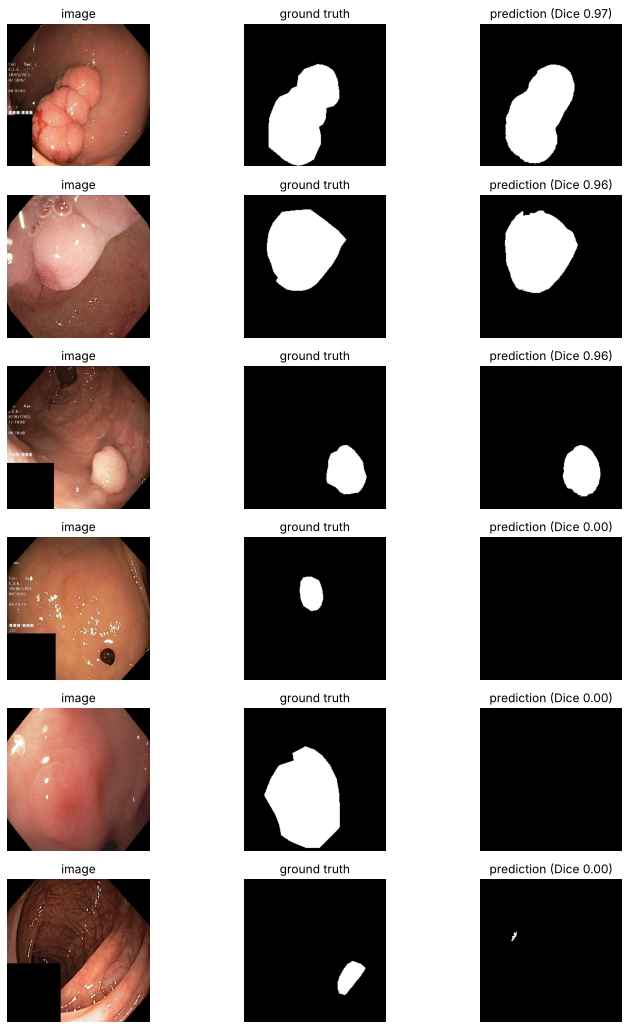

In [ ]:
order = np.argsort(scores[:, 0])
show = list(order[::-1][:3]) + list(order[:3])
plt.figure(figsize=(12, 18))
for r, i in enumerate(show):
    plt.subplot(6, 3, 3 * r + 1); plt.imshow(X_test[i]); plt.axis('off'); plt.title('image')
    plt.subplot(6, 3, 3 * r + 2); plt.imshow(Y_test[i, :, :, 0], cmap='gray'); plt.axis('off'); plt.title('ground truth')
    plt.subplot(6, 3, 3 * r + 3); plt.imshow(pred_test[i, :, :, 0], cmap='gray'); plt.axis('off')
    plt.title(f'prediction (Dice {scores[i, 0]:.2f})')
plt.show()

## 실습
1. **지름길의 역할**: `build_unet(skip=False)`로 수축 경로의 특성 맵을 이어 붙이지 않는 모델을 만들어 같은 방법으로 학습하고, 테스트 Dice와 예측 마스크를 비교해 보세요.
2. **임계값**: 예측 확률을 마스크로 바꾸는 임계값을 0.3, 0.5, 0.7로 바꿔 테스트 Dice를 비교해 보세요.

먼저 직접 작성해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [ ]:
# 직접 작성해 보세요


### 예시 답안

In [15]:
# 1. 지름길을 뺀 모델
tf.keras.utils.set_random_seed(42)
model_noskip = build_unet(skip=False)
model_noskip.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                     loss=bce_dice_loss, metrics=[dice_coef])
early2 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                          restore_best_weights=True)
history_noskip = model_noskip.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                                  epochs=60, batch_size=16, callbacks=[early2], verbose=2)

pred_noskip = model_noskip.predict(X_test, verbose=0) > 0.5
scores_noskip = np.array([dice_iou(Y_test[i] > 0.5, pred_noskip[i]) for i in range(len(X_test))])
print(f"지름길 있음 Dice {scores[:, 0].mean():.3f}, IoU {scores[:, 1].mean():.3f}")
print(f"지름길 없음 Dice {scores_noskip[:, 0].mean():.3f}, IoU {scores_noskip[:, 1].mean():.3f}")

Epoch 1/60
50/50 - 19s - 382ms/step - dice_coef: 0.2129 - loss: 1.3053 - val_dice_coef: 0.2505 - val_loss: 1.2346
Epoch 2/60
50/50 - 8s - 157ms/step - dice_coef: 0.2559 - loss: 1.1512 - val_dice_coef: 0.2822 - val_loss: 1.0987
Epoch 3/60
50/50 - 8s - 162ms/step - dice_coef: 0.2900 - loss: 1.0829 - val_dice_coef: 0.3347 - val_loss: 1.0464
Epoch 4/60
50/50 - 8s - 167ms/step - dice_coef: 0.3094 - loss: 1.0834 - val_dice_coef: 0.3038 - val_loss: 1.1842
Epoch 5/60
50/50 - 8s - 163ms/step - dice_coef: 0.3215 - loss: 1.0757 - val_dice_coef: 0.3058 - val_loss: 1.1999
Epoch 6/60
50/50 - 8s - 157ms/step - dice_coef: 0.3584 - loss: 1.0475 - val_dice_coef: 0.3213 - val_loss: 1.0950
Epoch 7/60
50/50 - 8s - 154ms/step - dice_coef: 0.3430 - loss: 1.0277 - val_dice_coef: 0.4053 - val_loss: 1.0208
Epoch 8/60
50/50 - 8s - 153ms/step - dice_coef: 0.4254 - loss: 0.9457 - val_dice_coef: 0.3966 - val_loss: 0.9985
Epoch 9/60
50/50 - 8s - 153ms/step - dice_coef: 0.4115 - loss: 0.9488 - val_dice_coef: 0.4115 -

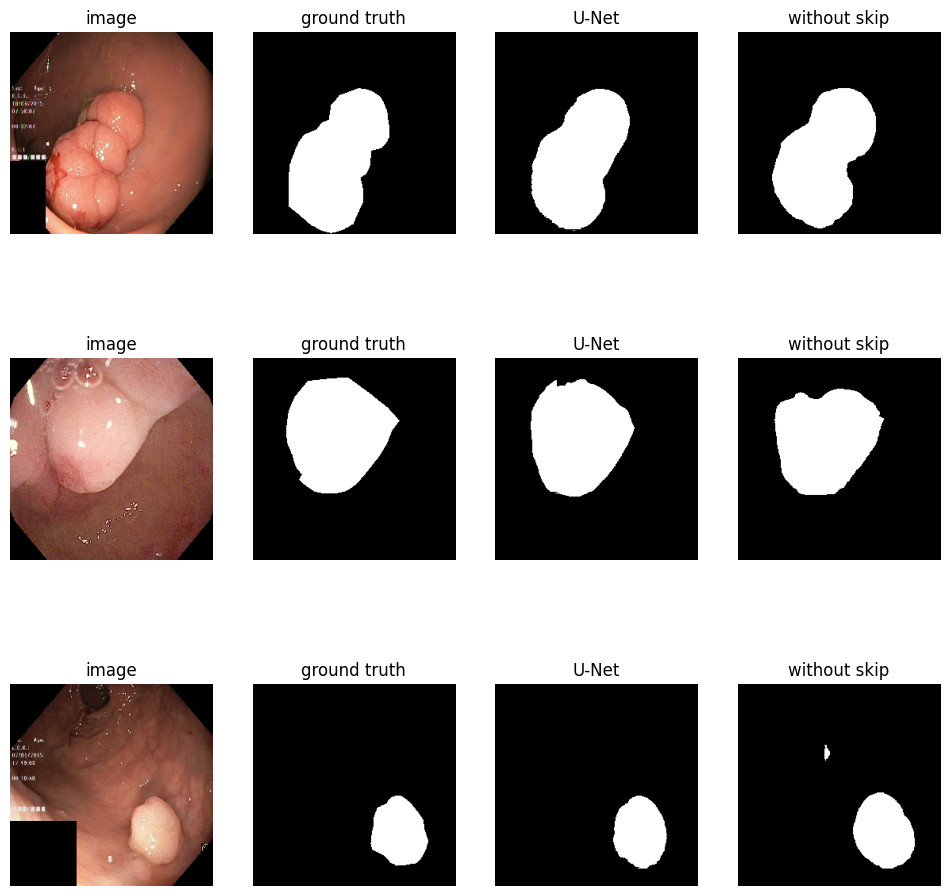

In [16]:
plt.figure(figsize=(12, 12))
for r, i in enumerate(order[::-1][:3]):
    plt.subplot(3, 4, 4 * r + 1); plt.imshow(X_test[i]); plt.axis('off'); plt.title('image')
    plt.subplot(3, 4, 4 * r + 2); plt.imshow(Y_test[i, :, :, 0], cmap='gray'); plt.axis('off'); plt.title('ground truth')
    plt.subplot(3, 4, 4 * r + 3); plt.imshow(pred_test[i, :, :, 0], cmap='gray'); plt.axis('off'); plt.title('U-Net')
    plt.subplot(3, 4, 4 * r + 4); plt.imshow(pred_noskip[i, :, :, 0], cmap='gray'); plt.axis('off'); plt.title('without skip')
plt.show()

In [17]:
# 2. 임계값 바꾸기
for t in [0.3, 0.5, 0.7]:
    s = np.array([dice_iou(Y_test[i] > 0.5, prob_test[i] > t) for i in range(len(X_test))])
    print(f"임계값 {t}: Dice {s[:, 0].mean():.3f}, IoU {s[:, 1].mean():.3f}")

임계값 0.3: Dice 0.667, IoU 0.564
임계값 0.5: Dice 0.662, IoU 0.563
임계값 0.7: Dice 0.652, IoU 0.557
